# Exploration: CW rendezvous
Interactive scratchpad using the `src` package. Run from the `notebooks/` folder or repo root.

In [1]:
import sys, pathlib
root = pathlib.Path.cwd()
root = root if (root/'src').exists() else root.parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
from src.config import Scenario
from src.simulation import run_simulation
from src import visualization as viz
from src.analysis import parameter_sweep, dv_curve

## Default scenario (400 km, y0 = -1 km, 30 min)

RENDEZVOUS ACHIEVED
dv total [m/s]: 1.1188211398141814


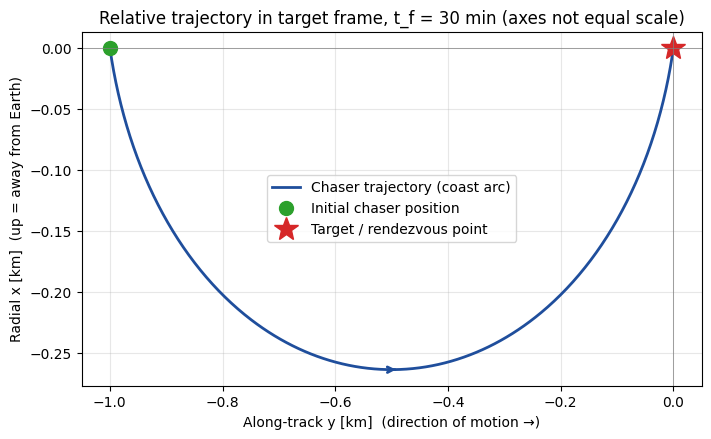

In [2]:
res = run_simulation(Scenario())
print(res.status)
print('dv total [m/s]:', res.solution.dv_total*1000)
viz.plot_trajectory(res); plt.show()

## Effect of an initial radial offset
With x0 != 0 the burn plan changes; the solver is still closed-form.

In [3]:
for x0 in (0.0, 0.1, 0.2):
    r = run_simulation(Scenario(x0_km=x0))
    print(f'x0={x0:.1f} km  dv_total={r.solution.dv_total*1000:.4f} m/s  status={r.status}')

x0=0.0 km  dv_total=1.1188 m/s  status=RENDEZVOUS ACHIEVED
x0=0.1 km  dv_total=1.2721 m/s  status=RENDEZVOUS ACHIEVED
x0=0.2 km  dv_total=1.4730 m/s  status=RENDEZVOUS ACHIEVED


## Sweep table

In [4]:
df = parameter_sweep()
df[['separation_km','transfer_time_min','dv_total_m_s','final_separation_m','final_rel_speed_m_s','status']].round(4)

,separation_km,transfer_time_min,dv_total_m_s,final_separation_m,final_rel_speed_m_s,status
0,0.5,10.0,1.7573,0.0,0.0,RENDEZVOUS ACHIEVED
1,0.5,20.0,0.9020,0.0,0.0,RENDEZVOUS ACHIEVED
2,0.5,30.0,0.5594,0.0,0.0,RENDEZVOUS ACHIEVED
3,0.5,40.0,0.3649,0.0,0.0,RENDEZVOUS ACHIEVED
4,0.5,60.0,0.1650,0.0,0.0,RENDEZVOUS ACHIEVED
5,1.0,10.0,3.5147,0.0,0.0,RENDEZVOUS ACHIEVED
6,1.0,20.0,1.8041,0.0,0.0,RENDEZVOUS ACHIEVED
7,1.0,30.0,1.1188,0.0,0.0,RENDEZVOUS ACHIEVED
8,1.0,40.0,0.7298,0.0,0.0,RENDEZVOUS ACHIEVED
9,1.0,60.0,0.3300,0.0,0.0,RENDEZVOUS ACHIEVED
